In [1]:
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False

In [2]:
import duckdb
import pandas as pd
import geopandas as gpd
from shapely import wkb
import matplotlib.pyplot as plt
import scipy.stats as st
import contextily as cx
import numpy as np
import xyzservices.providers as xyz

import multiprocessing
num_cores = multiprocessing.cpu_count()

In [3]:
%load_ext sql
conn = duckdb.connect()
%sql conn --alias duckdb

Tip: You may define configurations in /Users/saadiqmohiuddin/Documents/gtfs-realtime-etl/notebooks/pyproject.toml or /Users/saadiqmohiuddin/.jupysql/config.

Did not find user configurations in /Users/saadiqmohiuddin/Documents/gtfs-realtime-etl/notebooks/pyproject.toml.

In [4]:
agency = 'stm'
timezones = {
    "ttc": 'America/Toronto',
    "octranspo": 'America/Toronto',
    "calgary": 'America/Edmonton',
    "edmonton": 'America/Edmonton',
    "stm": 'America/Toronto'
}

In [5]:
%%sql
INSTALL cache_httpfs FROM community;
LOAD cache_httpfs;
-- SET cache_httpfs_max_fanout_subrequest=40;
-- SET cache_httpfs_cache_block_size=4096;
CREATE SECRET my_secret (
    TYPE S3,
    REGION 'us-west-2'
);

INSTALL spatial;
LOAD spatial;
SET threads = {{num_cores*5}};
SET parquet_metadata_cache = true;

SET GLOBAL timezone='{{timezones.get(agency)}}';

,Success


In [6]:
%%sql
CREATE TABLE IF NOT EXISTS trips AS
    SELECT * FROM read_csv('data/{{agency}}/trips.txt');

CREATE TABLE IF NOT EXISTS stops AS
SELECT
    *,
    ST_Point(stop_lon, stop_lat) AS stop_loc
FROM read_csv('data/{{agency}}/stops.txt', types={'stop_id': 'VARCHAR'});

CREATE TABLE IF NOT EXISTS routes AS
    SELECT * FROM read_csv('data/{{agency}}/routes.txt');

CREATE TABLE IF NOT EXISTS shapes AS
    SELECT * FROM read_csv('data/{{agency}}/shapes.txt');

CREATE TABLE IF NOT EXISTS stop_times AS
    SELECT * FROM read_csv('data/{{agency}}/stop_times.txt', types={'stop_id': 'VARCHAR'});

,Count
0,9079282


In [7]:
%%sql 
CREATE VIEW IF NOT EXISTS locations AS
SELECT * FROM read_parquet('s3://gtfs-rt-etl-data/{{agency}}/positions/year=*/month=*/day=*/*.parquet', hive_partitioning = true) where month=10;
FROM (DESCRIBE locations);

,column_name,column_type,null,key,default,extra
0,trip_id,VARCHAR,YES,None,None,None
1,route_id,VARCHAR,YES,None,None,None
2,direction_id,VARCHAR,YES,None,None,None
3,vehicle_id,VARCHAR,YES,None,None,None
4,bearing,DOUBLE,YES,None,None,None
5,speed,DOUBLE,YES,None,None,None
6,timestamp,TIMESTAMP WITH TIME ZONE,YES,None,None,None
7,geohash,VARCHAR,YES,None,None,None
8,geometry,GEOMETRY,YES,None,None,None
9,bbox,"STRUCT(xmin DOUBLE, ymin DOUBLE, xmax DOUBLE, ...",YES,None,None,None


In [8]:
%sql select count(*) from locations;

,count_star()
0,14104838


In [9]:
%%time
%%sql
df <<WITH first_arrivals AS (
    SELECT 
        X.trip_id,
        S.stop_id,
        V.stop_loc,
        MIN(Y.timestamp)::timestamp AS first_ts
    FROM routes AS T
    JOIN trips AS X ON T.route_id = X.route_id
    JOIN stop_times AS S ON X.trip_id = S.trip_id
    JOIN stops AS V ON S.stop_id = V.stop_id
    JOIN locations AS Y
        ON X.trip_id = Y.trip_id
       AND Y.bbox.xmax >= V.stop_lon - 0.001
       AND Y.bbox.xmin <= V.stop_lon + 0.001
       AND Y.bbox.ymax >= V.stop_lat - 0.001
       AND Y.bbox.ymin <= V.stop_lat + 0.001
       AND ST_DWithin(Y.geometry, V.stop_loc, 0.0002)
    WHERE T.route_type IN (3, 700)
    GROUP BY X.trip_id, S.stop_id, V.stop_loc
),
ordered AS (
    SELECT
        stop_id,
        stop_loc,
        DATE_TRUNC('day', first_ts) AS service_date,
        first_ts,
        LAG(first_ts) OVER (
            PARTITION BY stop_id, DATE_TRUNC('day', first_ts)
            ORDER BY first_ts
        ) AS prev_ts
    FROM first_arrivals
),
headways AS (
    SELECT
        stop_id,
        stop_loc,
        service_date,
        EXTRACT(EPOCH FROM (first_ts - prev_ts)) / 60.0 AS headway_minutes
    FROM ordered
    WHERE prev_ts IS NOT NULL
      AND EXTRACT(EPOCH FROM (first_ts - prev_ts)) / 60.0 BETWEEN 0 AND 120
)
SELECT
    stop_id,
    ST_AsHEXWKB(stop_loc) AS geometry,
    AVG(headway_minutes) AS avg_headway_minutes_per_day
FROM headways
GROUP BY stop_id, stop_loc
ORDER BY stop_id;





CPU times: user 6.91 s, sys: 2.67 s, total: 9.58 s
Wall time: 16.7 s


RuntimeError: Query interrupted

In [10]:
%%sql
df <<WITH first_arrival AS (
    SELECT
        T.route_id,
        X.trip_id,
        S.stop_id,
        V.stop_loc,
        MIN(strftime(Y.timestamp, '%H:%M:%S')::TIME) AS ts
    FROM routes AS T
    JOIN trips AS X ON T.route_id = X.route_id
    JOIN stop_times AS S ON X.trip_id = S.trip_id
    JOIN stops AS V ON S.stop_id = V.stop_id
    JOIN locations AS Y
        ON X.trip_id = Y.trip_id
       AND Y.bbox.xmax >= V.stop_lon - 0.001
       AND Y.bbox.xmin <= V.stop_lon + 0.001
       AND Y.bbox.ymax >= V.stop_lat - 0.001
       AND Y.bbox.ymin <= V.stop_lat + 0.001
       AND ST_DWithin(Y.geometry, V.stop_loc, 0.0002)
    WHERE NOT regexp_matches(S.arrival_time,'^(2[4-9]|3[0-5]):', 'c')
    AND T.route_type IN (3, 700)
    GROUP BY T.route_id, X.trip_id, S.stop_id, V.stop_loc
),
ordered AS (
    SELECT DISTINCT
        route_id,
        stop_id,
        stop_loc,
        ts,
        LAG(ts) OVER ( PARTITION BY stop_id, route_id ORDER BY stop_id, route_id, ts ) AS prev_ts
    FROM first_arrival
),
headways AS (
    SELECT
        route_id,
        stop_id,
        stop_loc,
        date_diff('seconds', prev_ts, ts) / 60.0 AS headway_minutes
    FROM ordered
    WHERE prev_ts IS NOT NULL
      AND ts > prev_ts                
),
route_avg AS (
    SELECT
        route_id,
        stop_id,
        stop_loc,
        AVG(headway_minutes) AS avg_headway_minutes_per_route,
        COUNT(*) AS n_intervals
    FROM headways
    GROUP BY route_id, stop_id, stop_loc
    HAVING COUNT(*) > 10                 -- only stable per-route headways
),
stop_avg AS (
    SELECT
        stop_id,
        stop_loc,
        AVG(avg_headway_minutes_per_route) AS avg_headway_minutes,
        COUNT(DISTINCT route_id) AS n_routes
    FROM route_avg
    GROUP BY stop_id, stop_loc
)
SELECT stop_id, ST_AsHEXWKB(stop_loc) AS geometry, avg_headway_minutes AS avg_headway_minutes_per_day
FROM stop_avg
ORDER BY avg_headway_minutes_per_day;

In [11]:
df['geometry'] = df['geometry'].apply(wkb.loads)

# Create the GeoDataFrame, specifying the geometry column
gdf = gpd.GeoDataFrame(df, geometry='geometry', crs="EPSG:4326")
gdf = gdf.to_crs(epsg=3857)
gdf.head()

,stop_id,geometry,avg_headway_minutes_per_day
0,62108,POINT (-8197649.122 5715546.235),2.280425
1,62104,POINT (-8196781.052 5714373.04),2.301242
2,50110,POINT (-8197732.166 5693312.138),2.302976
3,62094,POINT (-8193473.862 5711993.24),2.330052
4,62092,POINT (-8192219.959 5711201.334),2.333333


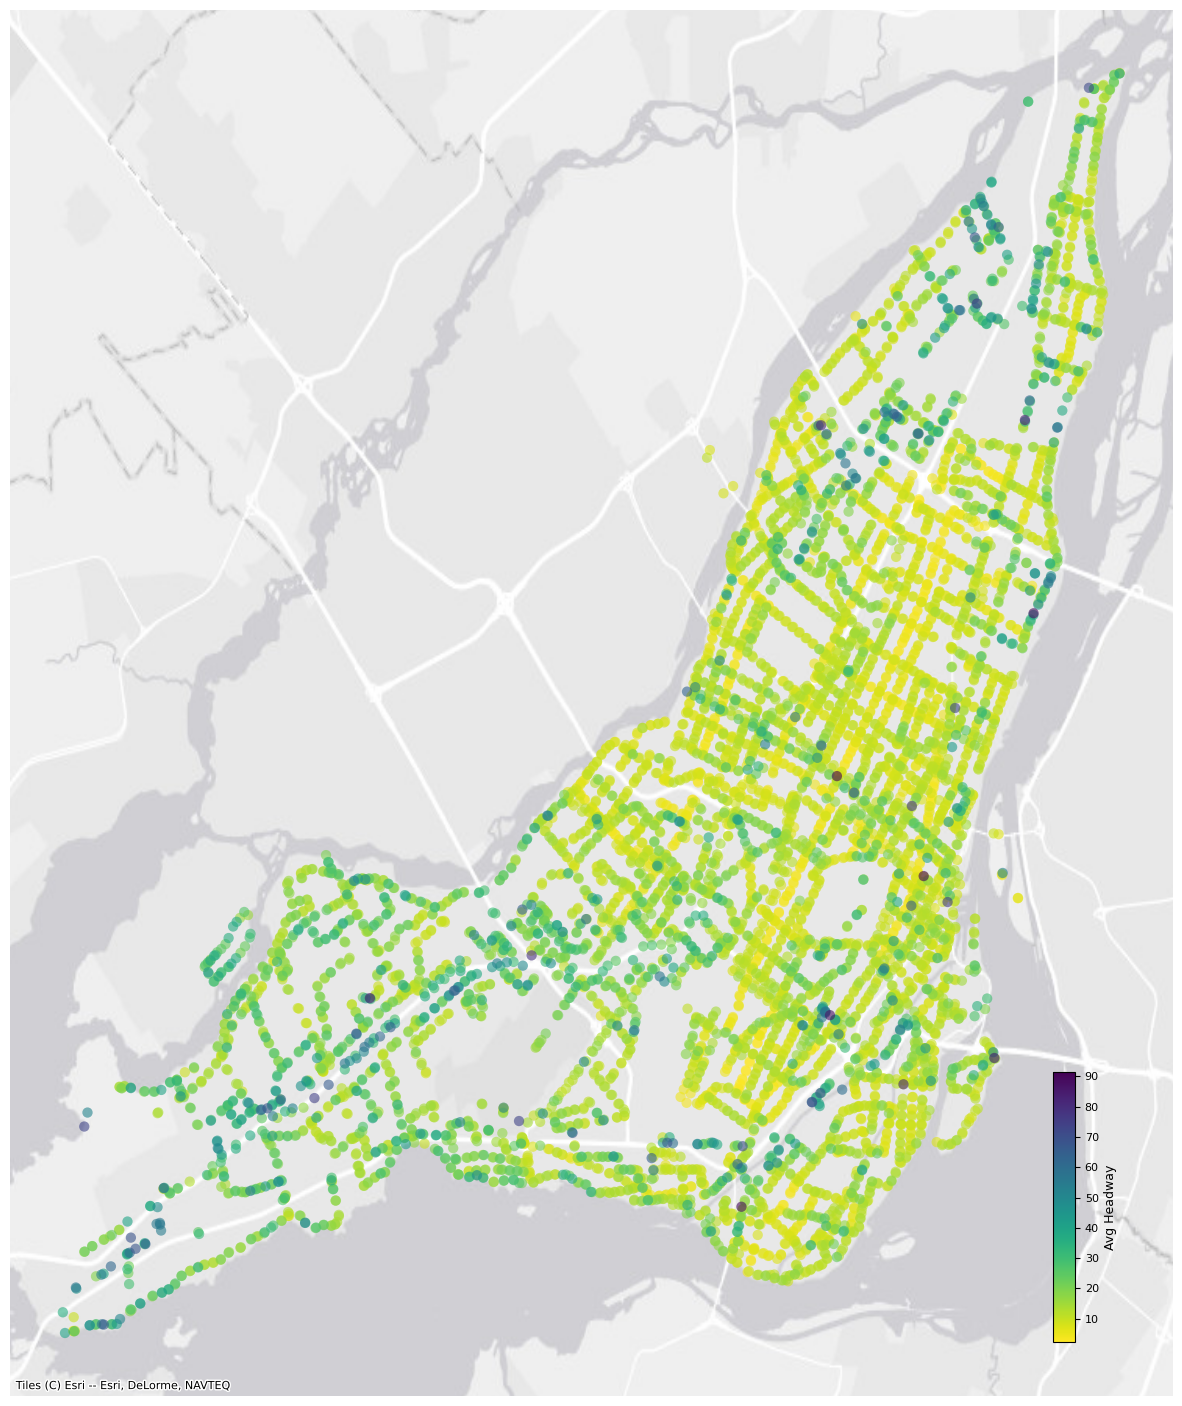

In [12]:
fig, ax = plt.subplots(figsize=(15, 18))

a, b = 150, 0.01
sizes = a * np.exp(b * (1 - gdf["avg_headway_minutes_per_day"]))

sc = ax.scatter(
    gdf.geometry.x,
    gdf.geometry.y,
    c=gdf["avg_headway_minutes_per_day"],
    s=55,
    cmap="viridis_r",
    alpha=0.6,
    edgecolors="none" 
)
cx.add_basemap(ax, source=xyz.Esri.WorldGrayCanvas)

sm = plt.cm.ScalarMappable(
    cmap="viridis_r", 
    norm=plt.Normalize(vmin=gdf["avg_headway_minutes_per_day"].min(), vmax=gdf["avg_headway_minutes_per_day"].max())
)
cax = fig.add_axes([0.82, 0.14, 0.015, 0.15]) 

# Draw the colorbar in that axes
cbar = plt.colorbar(sm, cax=cax)
cbar.ax.tick_params(labelsize=8)
cbar.set_label("Avg Headway", fontsize=9)
ax.set_axis_off()

# Save & show
plt.savefig(f"headway_{agency}.png", bbox_inches="tight", dpi=300)
plt.show()

In [13]:
%%sql
df << WITH ordered AS (
    SELECT DISTINCT
        X.route_id,
        S.stop_id,
        V.stop_loc,
        S.arrival_time::TIME as ts,
        LAG(ts) OVER ( PARTITION BY S.stop_id, X.route_id ORDER BY S.stop_id, X.route_id, ts ) AS prev_ts
    FROM routes AS T
    JOIN trips AS X ON T.route_id = X.route_id
    JOIN stop_times AS S ON X.trip_id = S.trip_id
    JOIN stops AS V ON S.stop_id = V.stop_id
    WHERE NOT regexp_matches(S.arrival_time,'^(2[4-9]|3[0-5]):', 'c')
    AND T.route_type IN (3, 700)
),
headways AS (
    SELECT
        route_id,
        stop_id,
        stop_loc,
        date_diff('seconds', prev_ts, ts) / 60.0 AS headway_minutes
    FROM ordered
    WHERE prev_ts IS NOT NULL
      AND ts > prev_ts                
),
route_avg AS (
    SELECT
        route_id,
        stop_id,
        stop_loc,
        AVG(headway_minutes) AS avg_headway_minutes_per_route,
        COUNT(*) AS n_intervals
    FROM headways
    GROUP BY route_id, stop_id, stop_loc
    HAVING COUNT(*) > 10                 -- only stable per-route headways
),
stop_avg AS (
    SELECT
        stop_id,
        stop_loc,
        AVG(avg_headway_minutes_per_route) AS avg_headway_minutes,
        COUNT(DISTINCT route_id) AS n_routes
    FROM route_avg
    GROUP BY stop_id, stop_loc
)
SELECT stop_id, ST_AsHEXWKB(stop_loc) AS geometry, avg_headway_minutes AS avg_headway_minutes_per_day
FROM stop_avg
ORDER BY avg_headway_minutes_per_day;

In [14]:
df['geometry'] = df['geometry'].apply(wkb.loads)

# Create the GeoDataFrame, specifying the geometry column
gdf = gpd.GeoDataFrame(df, geometry='geometry', crs="EPSG:4326")
gdf = gdf.to_crs(epsg=3857)
gdf.head()

,stop_id,geometry,avg_headway_minutes_per_day
0,50110,POINT (-8197732.166 5693312.138),2.306613
1,50741,POINT (-8197730.051 5693367.68),2.445415
2,54398,POINT (-8194363.082 5705590.189),2.601367
3,54110,POINT (-8193578.725 5692036.658),2.691211
4,53436,POINT (-8183579.785 5713073.4),2.699647


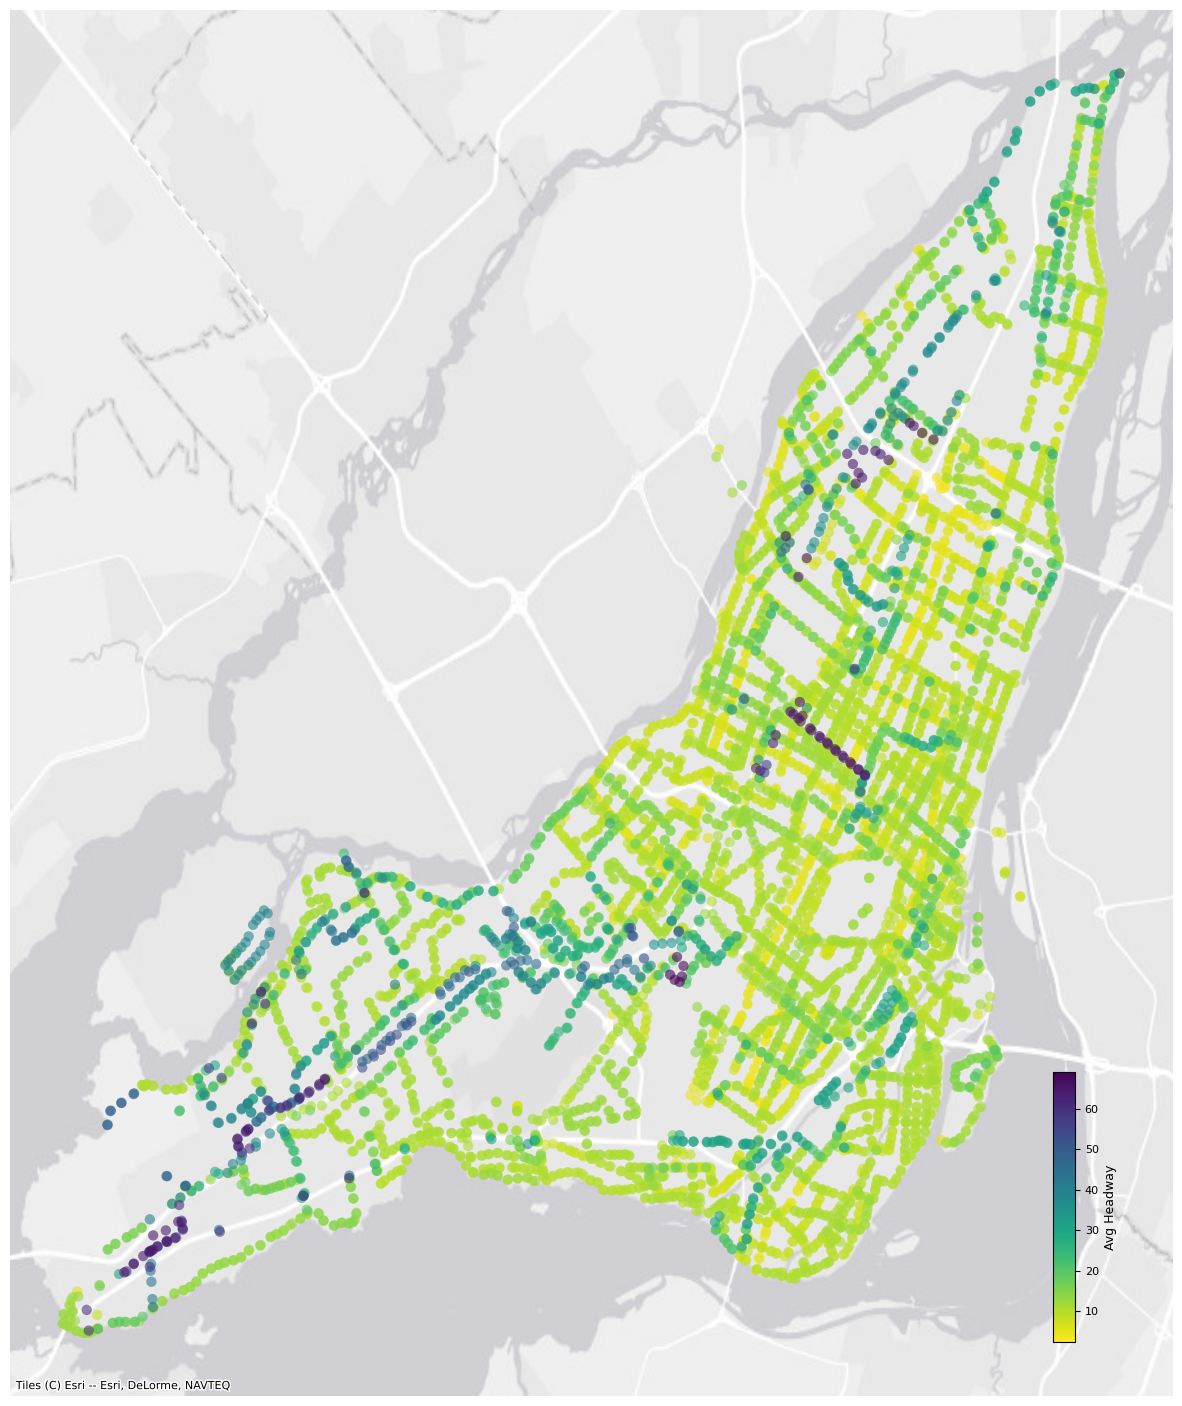

In [15]:
fig, ax = plt.subplots(figsize=(15, 18))

a, b = 120, 0.1
sizes = a * np.exp(b * (1 - gdf["avg_headway_minutes_per_day"]))

sc = ax.scatter(
    gdf.geometry.x,
    gdf.geometry.y,
    c=gdf["avg_headway_minutes_per_day"],
    s=55,
    cmap="viridis_r",
    alpha=0.6,
    edgecolors="none" 
)
cx.add_basemap(ax, source=xyz.Esri.WorldGrayCanvas)

sm = plt.cm.ScalarMappable(
    cmap="viridis_r", 
    norm=plt.Normalize(vmin=gdf["avg_headway_minutes_per_day"].min(), vmax=gdf["avg_headway_minutes_per_day"].max())
)
cax = fig.add_axes([0.82, 0.14, 0.015, 0.15]) 

# Draw the colorbar in that axes
cbar = plt.colorbar(sm, cax=cax)
cbar.ax.tick_params(labelsize=8)
cbar.set_label("Avg Headway", fontsize=9)
ax.set_axis_off()

# Save & show
plt.savefig(f"headway_{agency}.png", bbox_inches="tight", dpi=300)
plt.show()
